#recipe card
# 0. imports + device
# 1. DATA:   load → split → scale → tensors (dtypes!) → TensorDataset → DataLoader
# 2. MODEL:  class X(nn.Module): __init__ (layers) + forward (flow)
# 3. TRAIN:  model.train() → loop batches → forward → loss → zero_grad → backward → step
# 4. VALID:  model.eval() + no_grad → forward → loss → predictions → accuracy
# 5. RUN:    instantiate model/criterion/optimizer → epoch loop → plot losses


In [ ]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

indim= X_train.shape[1]  #Feature indexing

hiddendim=10
num_epochs=50
learning_rate=0.001
model = NN2Layer(indim,hiddendim).to(device)
criterion=nn.BCELoss()
optimizer=Adam(model.parameters(), lr=learning_rate)


# Run Training
train_losses = []
val_losses = []
val_accuracies = []

print('Starting Training...')
for epoch in range(num_epochs):
    # Train one epoch
    train_loss = train(model, optimizer, criterion, train_loader, device)

    # Validate
    val_loss, val_accuracy = validate(model, criterion, test_loader, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}')

print('Training Complete!')

Using device: cpu
Starting Training...
Epoch [5/50], Train Loss: 0.8708, Val Loss: 0.6735, Val Accuracy: 0.7456
Epoch [10/50], Train Loss: 0.6060, Val Loss: 0.5434, Val Accuracy: 0.7105
Epoch [15/50], Train Loss: 0.4845, Val Loss: 0.4661, Val Accuracy: 0.7982
Epoch [20/50], Train Loss: 0.4095, Val Loss: 0.4180, Val Accuracy: 0.8246
Epoch [25/50], Train Loss: 0.4173, Val Loss: 0.3822, Val Accuracy: 0.8509
Epoch [30/50], Train Loss: 0.3261, Val Loss: 0.3550, Val Accuracy: 0.8684
Epoch [35/50], Train Loss: 0.3023, Val Loss: 0.3282, Val Accuracy: 0.8947
Epoch [40/50], Train Loss: 0.2947, Val Loss: 0.3101, Val Accuracy: 0.8947
Epoch [45/50], Train Loss: 0.2724, Val Loss: 0.2966, Val Accuracy: 0.8947
Epoch [50/50], Train Loss: 0.2887, Val Loss: 0.2846, Val Accuracy: 0.8947
Training Complete!


In [1]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
import pandas as pd

import torch

In [3]:
data = load_breast_cancer()
X = data.data
y = data.target


X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test  = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_test  = torch.tensor(y_test, dtype=torch.float32)


In [5]:
#Create a Dataset
train_dataset = TensorDataset(X_train,y_train)
test_dataset = TensorDataset(X_test,y_test)

In [6]:
train_loader=DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
)
test_loader=DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
)
X_batch, y_batch = next(iter(train_loader))
print(f"Training batch input shape: {X_batch.shape}")
print(f"Training batch labels shape: {y_batch.shape}")


Training batch input shape: torch.Size([64, 30])
Training batch labels shape: torch.Size([64])


In [20]:
from torch import nn

class NN2Layer(nn.Module):
  def __init__(self,indim,hiddendim):
    super().__init__()
    self.layer1 = nn.Linear(indim,hiddendim)
    self.relu= nn.ReLU()
    self.layer2 = nn.Linear(hiddendim,1)
    self.sigmoid= nn.Sigmoid()

  def forward(self,X):
    z1 = self.layer1(X)
    a1= self.relu(z1)
    z2= self.layer2(a1)
    a2=self.sigmoid(z2)
    return a2


In [14]:
def train (model, optimizer,criterion,train_loader,device):

  model.train()
  running_loss=0
  for X_batch,y_batch in train_loader:
      X_batch=X_batch.to(device)
      y_batch= y_batch.view(-1,1).to(device)


      output= model(X_batch)
      loss= criterion(output,y_batch)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      running_loss+= loss.item()
  avg_loss= running_loss/len(train_loader)
  return avg_loss


In [24]:
def validate(model, criterion, test_loader, device): #prams w/o optimizer
    model.eval()     # Set the model to evaluation mode


    running_loss = 0.0 #define vars to acummulate - loss - correct answers - total
    correct = 0
    total = 0

    with torch.no_grad():  #FIRST loop- Disable gradient computation
        for X_batch, y_batch in test_loader:#SECOEND loop- loop through batches
            X_batch = X_batch.to(device) # Move batch to the selected device

            y_batch = y_batch.view(-1, 1).to(device)

            # Forward pass
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            running_loss += loss.item()

            # Binary predictions
            predicted = (outputs > 0.5).float()

            # Accuracy calculation
            correct += (predicted == y_batch).sum().item()
            total += y_batch.size(0)# حجم اول دايمنشن


    avg_loss = running_loss / len(test_loader)
    accuracy = correct / total

    return avg_loss, accuracy


In [10]:
from torch.optim import Adam
import matplotlib.pyplot as plt

In [25]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

indim= X_train.shape[1]  #Feature indexing

hiddendim=10
num_epochs=50
learning_rate=0.001
model = NN2Layer(indim,hiddendim).to(device)
criterion=nn.BCELoss()
optimizer=Adam(model.parameters(), lr=learning_rate)


# Run Training
train_losses = []
val_losses = []
val_accuracies = []

print('Starting Training...')
for epoch in range(num_epochs):
    # Train one epoch
    train_loss = train(model, optimizer, criterion, train_loader, device)

    # Validate
    val_loss, val_accuracy = validate(model, criterion, test_loader, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}')

print('Training Complete!')

Using device: cpu
Starting Training...
Epoch [5/50], Train Loss: 0.8708, Val Loss: 0.6735, Val Accuracy: 0.7456
Epoch [10/50], Train Loss: 0.6060, Val Loss: 0.5434, Val Accuracy: 0.7105
Epoch [15/50], Train Loss: 0.4845, Val Loss: 0.4661, Val Accuracy: 0.7982
Epoch [20/50], Train Loss: 0.4095, Val Loss: 0.4180, Val Accuracy: 0.8246
Epoch [25/50], Train Loss: 0.4173, Val Loss: 0.3822, Val Accuracy: 0.8509
Epoch [30/50], Train Loss: 0.3261, Val Loss: 0.3550, Val Accuracy: 0.8684
Epoch [35/50], Train Loss: 0.3023, Val Loss: 0.3282, Val Accuracy: 0.8947
Epoch [40/50], Train Loss: 0.2947, Val Loss: 0.3101, Val Accuracy: 0.8947
Epoch [45/50], Train Loss: 0.2724, Val Loss: 0.2966, Val Accuracy: 0.8947
Epoch [50/50], Train Loss: 0.2887, Val Loss: 0.2846, Val Accuracy: 0.8947
Training Complete!


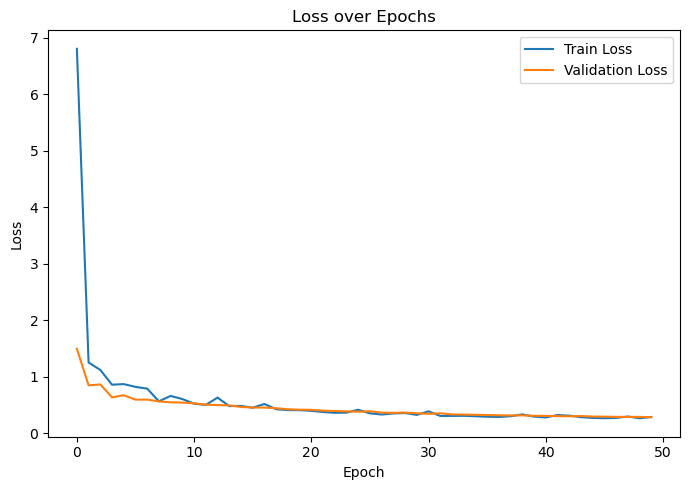

In [26]:
# Plotting results
plt.figure(figsize=(7, 5))

plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()